# Bước 8A — Đo tốc độ pipeline nhận diện

**Đồ án CV nâng cao · 16/11/2026**

Câu hỏi: trên máy của nhóm, một khung hình webcam mất bao lâu để xử lý, và phần nào chậm nhất?

Pipeline đo là đúng code của app demo (`demo/nhan_dien.py`): MTCNN tìm mặt và cắt 160×160 → InceptionResnetV1 trích embedding → so cosine với gallery. Mỗi lần xử lý một khung hình (batch = 1), như khi chạy webcam.

Khung hình thử là ảnh gốc của ROF (ảnh toàn cảnh có người thật), đưa về 640×480 như webcam. Ảnh ROF ở đây chỉ làm đầu vào để bấm giờ; notebook không chấm đúng/sai và không chọn tham số nào từ chúng.

## 1. Cách đo

- Chạy làm nóng 15 khung hình trước khi bấm giờ.
- Với GPU, gọi `torch.cuda.synchronize()` trước và sau mỗi đoạn để thời gian đo là thời gian tính thật.
- Tách ba đoạn: **tìm + cắt mặt**, **trích embedding**, **tìm trong gallery** (144 người, bằng số người quen của ROF). Tổng ba đoạn là thời gian xử lý một khung hình.
- Báo trung vị và phân vị 95 (p95), kèm số khung hình đo.
- **Không gồm** thời gian đọc camera và vẽ giao diện; phần vẽ được đo riêng ở mục 4. FPS hiển thị thật của app sẽ thấp hơn FPS tính từ thời gian xử lý.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import os, sys, json, time, platform, ctypes, importlib.metadata, warnings
warnings.filterwarnings('ignore', message='IProgress not found')
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import torch


def find_root():
    options = [Path(os.environ['CV_PROJECT_ROOT'])] if os.environ.get('CV_PROJECT_ROOT') else []
    options += [Path.cwd(), *Path.cwd().parents]
    for p in options:
        if (p / 'ban_giao_nhom/do_toc_do/Do_toc_do_pipeline.ipynb').is_file():
            return p.resolve()
    raise FileNotFoundError('Mở notebook trong thư mục dự án hoặc đặt CV_PROJECT_ROOT')


ROOT = find_root()
HERE = ROOT / 'ban_giao_nhom/do_toc_do'
OUT = HERE / 'notebook_outputs'; TAB, FIG = OUT / 'tables', OUT / 'figures'
for p in [OUT, TAB, FIG]:
    p.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / 'ban_giao_nhom/demo'))
from nhan_dien import FacePipeline, Gallery, MTCNN_CONFIG
from webcam_demo import annotate

SEED = 20261028
CFG = {'frame_size': [640, 480], 'frames_gpu': 240, 'frames_cpu': 240, 'warmup_frames': 15, 'gallery_size': 144,
       'batch': 1, 'mtcnn': MTCNN_CONFIG}
START = time.perf_counter()


def save(d, name):
    d.to_csv(TAB / (name + '.csv'), index=False, encoding='utf-8-sig'); return d


def vn(x, d=1):
    return f'{x:,.{d}f}'.replace(',', '_').replace('.', ',').replace('_', '.')


def finish(fig, name):
    for ext in ['png', 'svg']:
        fig.savefig(FIG / (name + '.' + ext), bbox_inches='tight', dpi=160)
    display(fig); plt.close(fig)


def power_source():
    class Status(ctypes.Structure):
        _fields_ = [('ACLineStatus', ctypes.c_byte), ('BatteryFlag', ctypes.c_byte), ('BatteryLifePercent', ctypes.c_byte),
                    ('SystemStatusFlag', ctypes.c_byte), ('BatteryLifeTime', ctypes.c_ulong), ('BatteryFullLifeTime', ctypes.c_ulong)]
    try:
        s = Status(); ctypes.windll.kernel32.GetSystemPowerStatus(ctypes.byref(s))
        return {1: 'cắm sạc', 0: 'chạy pin'}.get(s.ACLineStatus, 'không rõ')
    except Exception:
        return 'không rõ'


plt.rcParams.update({'font.family': 'Arial', 'figure.dpi': 110, 'axes.unicode_minus': False,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e4e3df', 'grid.linewidth': .6})
STAGE_COLORS = {'Tìm + cắt mặt': '#2a78d6', 'Trích embedding': '#eb6834', 'Tìm trong gallery': '#1baf7a'}
HAS_GPU = torch.cuda.is_available()
ENV = {'máy': platform.node(), 'CPU': platform.processor(), 'số luồng CPU của torch': torch.get_num_threads(),
       'GPU': torch.cuda.get_device_name(0) if HAS_GPU else 'không có', 'nguồn điện': power_source(),
       'python': platform.python_version(), 'torch': torch.__version__,
       'facenet_pytorch': importlib.metadata.version('facenet-pytorch'),
       'khung hình': '640×480, batch 1', 'min_face_size MTCNN': MTCNN_CONFIG['min_face_size']}
display(pd.DataFrame([{'mục': k, 'giá trị': str(v)} for k, v in ENV.items()]))
if ENV['nguồn điện'] != 'cắm sạc':
    display(Markdown('**Lưu ý:** máy không cắm sạc, GPU laptop thường bị giảm xung. Số đo bên dưới có thể chậm hơn lúc cắm sạc.'))

,mục,giá trị
0,máy,DESKTOP-N65CLUF
1,CPU,"AMD64 Family 25 Model 97 Stepping 2, AuthenticAMD"
2,số luồng CPU của torch,16
3,GPU,NVIDIA GeForce RTX 4060 Laptop GPU
4,nguồn điện,cắm sạc
5,python,3.11.9
6,torch,2.2.2+cu121
7,facenet_pytorch,2.6.0
8,khung hình,"640×480, batch 1"
9,min_face_size MTCNN,20


## 2. Khung hình thử

Lấy ảnh gốc ROF theo thứ tự tên file (tên là mã băm nên coi như ngẫu nhiên), giữ tỷ lệ và đặt vào khung 640×480 nền đen. Notebook ghi lại detector thấy bao nhiêu mặt ở từng khung, vì khung không có mặt chỉ tốn đoạn tìm mặt.

Đã nạp **240 khung hình** 640×480 từ `data/raw/rof_originals/`.

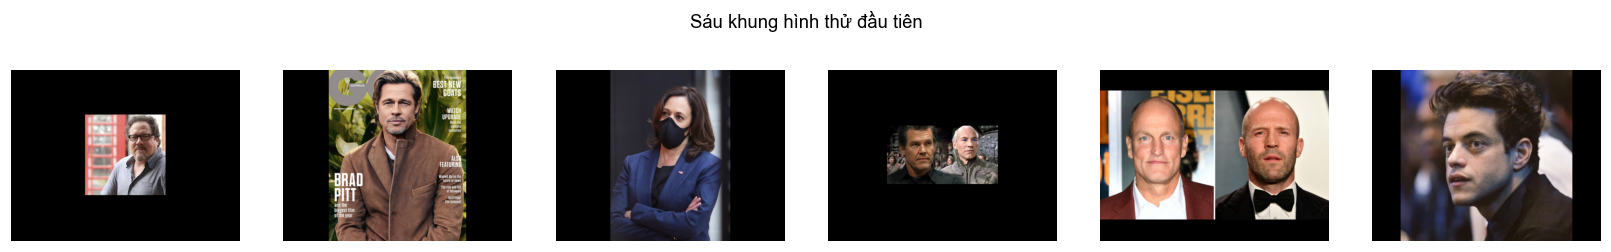

In [2]:
def letterbox(im, size=(640, 480)):
    im = ImageOps.exif_transpose(im).convert('RGB')
    im.thumbnail(size, Image.Resampling.BILINEAR)
    canvas = Image.new('RGB', size, (0, 0, 0))
    canvas.paste(im, ((size[0] - im.width) // 2, (size[1] - im.height) // 2))
    return canvas


source_dir = ROOT / 'data/raw/rof_originals'
FRAMES, names = [], []
for path in sorted(source_dir.iterdir()):
    try:
        with Image.open(path) as im:
            FRAMES.append(letterbox(im)); names.append(path.name)
    except Exception:
        continue                      # file tải lỗi, không phải ảnh
    if len(FRAMES) == CFG['frames_gpu']:
        break
assert len(FRAMES) == CFG['frames_gpu'], 'Không đủ ảnh gốc ROF trong data/raw/rof_originals'
display(Markdown(f'Đã nạp **{len(FRAMES)} khung hình** 640×480 từ `data/raw/rof_originals/`.'))
fig, axes = plt.subplots(1, 6, figsize=(15, 2.2))
for ax, im in zip(axes, FRAMES[:6]):
    ax.imshow(im); ax.axis('off')
fig.suptitle('Sáu khung hình thử đầu tiên', y=1.02); fig.tight_layout(); finish(fig, '01_sample_frames')

## 3. Đo từng đoạn trên GPU và CPU

Hai thiết bị đo trên cùng 240 khung hình. Gallery để bấm giờ gồm 144 vector đơn vị ngẫu nhiên (thời gian tìm chỉ phụ thuộc số người, không phụ thuộc nội dung vector). Encoder là B0; B1/B2 cùng kiến trúc nên cùng chi phí, mục 5 đo lại để xác nhận.

In [3]:
rng = np.random.default_rng(SEED)
templates = rng.normal(size=(CFG['gallery_size'], 512)).astype(np.float32)
templates /= np.linalg.norm(templates, axis=1, keepdims=True)
GALLERY = Gallery([f'P{i:03d}' for i in range(len(templates))], templates, {})


def sync(device):
    if device.startswith('cuda'):
        torch.cuda.synchronize()


def measure(device, frames):
    pipe = FacePipeline('B0', device=device)
    for im in frames[:CFG['warmup_frames']]:                       # làm nóng, không tính
        status, crop, _ = pipe.prepare_face(im)
        if crop is not None:
            pipe.encode([crop])
    rows, crops = [], []
    for i, im in enumerate(frames):
        sync(device); t0 = time.perf_counter()
        status, crop, meta = pipe.prepare_face(im)
        sync(device); t1 = time.perf_counter()
        t2 = t3 = t1
        if crop is not None:
            emb = pipe.encode([crop])[0]
            sync(device); t2 = time.perf_counter()
            GALLERY.predict(emb, 0.5); t3 = time.perf_counter()
            crops.append(crop)
        rows.append({'device': device, 'frame': i, 'status': status, 'n_faces': meta['n_faces'],
                     'detect_ms': 1000 * (t1 - t0), 'embed_ms': 1000 * (t2 - t1) if crop is not None else np.nan,
                     'search_ms': 1000 * (t3 - t2) if crop is not None else np.nan, 'total_ms': 1000 * (t3 - t0)})
    return pd.DataFrame(rows), pipe, crops


runs = []
PIPES, CROPS = {}, {}
devices = (['cuda:0'] if HAS_GPU else []) + ['cpu']
for device in devices:
    frames = FRAMES if device.startswith('cuda') else FRAMES[:CFG['frames_cpu']]
    frame_table, PIPES[device], CROPS[device] = measure(device, frames)
    runs.append(frame_table)
LAT = save(pd.concat(runs, ignore_index=True), '01_latency_per_frame')
status_table = LAT.groupby(['device', 'status']).size().unstack(fill_value=0)
display(status_table)


def q(s, p):
    return float(np.nanpercentile(s, p)) if s.notna().any() else np.nan


rows = []
for device, g in LAT.groupby('device'):
    one = g[g.status.eq('single_face')]
    for label, frame, col in [('Tìm + cắt mặt', one, 'detect_ms'), ('Trích embedding', one, 'embed_ms'),
                              ('Tìm trong gallery', one, 'search_ms'), ('Cả khung hình (có 1 mặt)', one, 'total_ms'),
                              ('Cả khung hình (không thấy mặt)', g[g.status.eq('no_face')], 'total_ms'),
                              ('Cả khung hình (mọi khung)', g, 'total_ms')]:
        if len(frame):
            rows.append({'thiết bị': 'GPU' if device.startswith('cuda') else 'CPU', 'đoạn': label, 'số khung': len(frame),
                         'trung vị (ms)': q(frame[col], 50), 'p95 (ms)': q(frame[col], 95), 'trung bình (ms)': float(frame[col].mean())})
SUMMARY = save(pd.DataFrame(rows), '02_latency_summary')
SUMMARY['FPS theo trung vị'] = np.where(SUMMARY['đoạn'].str.startswith('Cả khung'), 1000 / SUMMARY['trung vị (ms)'], np.nan)
display(SUMMARY.round(2))

status,multiple_faces,no_face,single_face
device,,,
cpu,61,1,178
cuda:0,61,1,178


,thiết bị,đoạn,số khung,trung vị (ms),p95 (ms),trung bình (ms),FPS theo trung vị
0,CPU,Tìm + cắt mặt,178,32.09,45.18,33.14,NaN
1,CPU,Trích embedding,178,31.91,35.45,32.08,NaN
2,CPU,Tìm trong gallery,178,0.28,0.36,0.28,NaN
3,CPU,Cả khung hình (có 1 mặt),178,64.17,77.74,65.50,15.58
4,CPU,Cả khung hình (không thấy mặt),1,17.00,17.00,17.00,58.82
5,CPU,Cả khung hình (mọi khung),240,62.00,76.66,58.86,16.13
6,GPU,Tìm + cắt mặt,178,39.28,59.26,41.10,NaN
7,GPU,Trích embedding,178,17.08,21.89,17.91,NaN
8,GPU,Tìm trong gallery,178,0.25,0.32,0.26,NaN
9,GPU,Cả khung hình (có 1 mặt),178,57.37,78.34,59.27,17.43


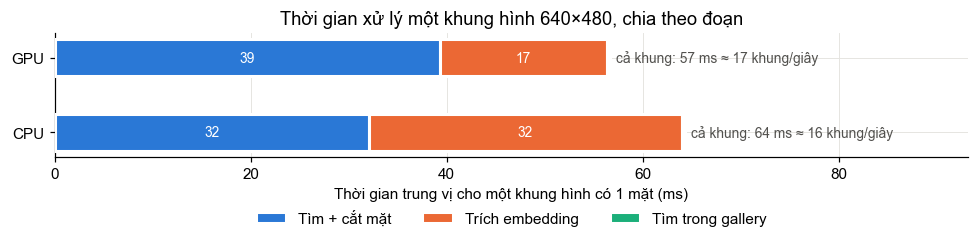

In [4]:
stages = list(STAGE_COLORS)
fig, ax = plt.subplots(figsize=(9, 2.6))
labels = [d for d in ['GPU', 'CPU'] if d in set(SUMMARY['thiết bị'])]
left = np.zeros(len(labels))
for stage in stages:
    vals = np.array([SUMMARY[(SUMMARY['thiết bị'] == d) & (SUMMARY['đoạn'] == stage)]['trung vị (ms)'].iloc[0] for d in labels])
    ax.barh(labels, vals, left=left, color=STAGE_COLORS[stage], label=stage, height=.5, edgecolor='white', linewidth=2, zorder=3)
    for y, (v, l) in enumerate(zip(vals, left)):
        if v >= 4:
            ax.text(l + v / 2, y, f'{v:.0f}', ha='center', va='center', color='white', fontsize=9, zorder=4)
    left += vals
for y, d in enumerate(labels):       # nhãn dùng trung vị cả khung hình (không phải tổng trung vị các đoạn)
    total = SUMMARY[(SUMMARY['thiết bị'] == d) & (SUMMARY['đoạn'] == 'Cả khung hình (có 1 mặt)')]['trung vị (ms)'].iloc[0]
    ax.text(left[y] + max(left) * .01, y, f'cả khung: {total:.0f} ms ≈ {1000 / total:.0f} khung/giây', va='center', fontsize=9, color='#52514e')
ax.set_xlim(0, max(left) * 1.45); ax.invert_yaxis()
ax.set(xlabel='Thời gian trung vị cho một khung hình có 1 mặt (ms)', title='Thời gian xử lý một khung hình 640×480, chia theo đoạn')
ax.legend(frameon=False, ncols=3, loc='upper center', bbox_to_anchor=(.5, -.32)); fig.tight_layout(); finish(fig, '02_latency_by_stage')

## 4. Thời gian vẽ giao diện và ảnh hưởng của số người trong gallery

Đo thêm hai thứ ngoài pipeline: (a) hàm vẽ khung, nhãn và dòng trạng thái của app demo, chạy trên CPU; (b) thời gian tìm trong gallery khi số người đăng ký tăng.

In [5]:
device = devices[0]
one_frames = [FRAMES[i] for i in LAT[(LAT.device == device) & LAT.status.eq('single_face')].frame.head(60)]
draw_ms = []
for im in one_frames:
    status, crop, meta = PIPES[device].prepare_face(im)
    result = {'detector_status': status, 'status': 'recognized', 'predicted_identity': 'W01', 'top_score': .71,
              'box': meta['boxes'][0], 'boxes': meta['boxes']}
    t0 = time.perf_counter()
    shown = annotate(im, result, 'B0 · ngưỡng 0.693 · 20 người · xử lý 40 ms · 20 FPS', crop)
    draw_ms.append(1000 * (time.perf_counter() - t0))
emb = PIPES[device].encode([CROPS[device][0]])[0]
scale_rows = []
for size in [20, 144, 1000, 10000]:
    t = rng.normal(size=(size, 512)).astype(np.float32); t /= np.linalg.norm(t, axis=1, keepdims=True)
    g = Gallery([str(i) for i in range(size)], t, {})
    for _ in range(50):
        g.predict(emb, .5)
    times = []
    for _ in range(500):
        t0 = time.perf_counter(); g.predict(emb, .5); times.append(1000 * (time.perf_counter() - t0))
    scale_rows.append({'số người trong gallery': size, 'trung vị (ms)': float(np.median(times)), 'p95 (ms)': float(np.percentile(times, 95))})
SCALE = save(pd.DataFrame(scale_rows), '03_gallery_search_scaling')
DRAW = {'số khung': len(draw_ms), 'trung vị (ms)': float(np.median(draw_ms)), 'p95 (ms)': float(np.percentile(draw_ms, 95))}
display(pd.DataFrame([{'đoạn': 'Vẽ giao diện (CPU)', **DRAW}]).round(2)); display(SCALE.round(4))

,đoạn,số khung,trung vị (ms),p95 (ms)
0,Vẽ giao diện (CPU),60,9.17,10.86


,số người trong gallery,trung vị (ms),p95 (ms)
0,20,0.0307,0.0530
1,144,0.1621,0.2170
2,1000,0.1680,0.2329
3,10000,0.1967,0.3518


## 5. B1, B2 có cùng tốc độ với B0 không?

Ba model cùng kiến trúc nên chi phí trích embedding phải như nhau. Đo lại đoạn trích embedding cho cả ba trên cùng các crop.

In [6]:
rows = []
crops = CROPS[device][:120]
for name in ['B0', 'B1', 'B2']:
    try:
        PIPES[device].set_model(name)
    except FileNotFoundError:
        rows.append({'model': name, 'ghi chú': 'không có file model'}); continue
    for c in crops[:10]:
        PIPES[device].encode([c])
    times = []
    for c in crops:
        sync(device); t0 = time.perf_counter(); PIPES[device].encode([c]); sync(device)
        times.append(1000 * (time.perf_counter() - t0))
    rows.append({'model': name, 'thiết bị': 'GPU' if device.startswith('cuda') else 'CPU', 'số crop': len(times),
                 'trung vị (ms)': float(np.median(times)), 'p95 (ms)': float(np.percentile(times, 95))})
PIPES[device].set_model('B0')
MODELS = save(pd.DataFrame(rows), '04_embedding_latency_by_model')
display(MODELS.round(2))

,model,thiết bị,số crop,trung vị (ms),p95 (ms)
0,B0,GPU,120,16.99,23.15
1,B1,GPU,120,16.60,22.91
2,B2,GPU,120,16.46,21.75


In [7]:
def row(device_label, stage):
    return SUMMARY[(SUMMARY['thiết bị'] == device_label) & (SUMMARY['đoạn'] == stage)].iloc[0]


lines = []
for label in [d for d in ['GPU', 'CPU'] if d in set(SUMMARY['thiết bị'])]:
    total = row(label, 'Cả khung hình (có 1 mặt)'); det = row(label, 'Tìm + cắt mặt'); emb_row = row(label, 'Trích embedding')
    lines.append(f"- **{label}:** một khung hình có 1 mặt mất trung vị **{vn(total['trung vị (ms)'])} ms** "
                 f"(p95 {vn(total['p95 (ms)'])} ms), tương đương khoảng **{1000 / total['trung vị (ms)']:.0f} khung/giây** phần xử lý. "
                 f"Tìm + cắt mặt {vn(det['trung vị (ms)'])} ms, trích embedding {vn(emb_row['trung vị (ms)'])} ms "
                 f"({100 * det['trung vị (ms)'] / total['trung vị (ms)']:.0f}% thời gian nằm ở detector). Đo trên {int(total['số khung'])} khung.")
search = SCALE.set_index('số người trong gallery')['trung vị (ms)']
if {'GPU', 'CPU'} <= set(SUMMARY['thiết bị']):
    ratio = row('CPU', 'Cả khung hình (có 1 mặt)')['trung vị (ms)'] / row('GPU', 'Cả khung hình (có 1 mặt)')['trung vị (ms)']
    if .75 <= ratio <= 1.33:
        lines.append(f"- **GPU và CPU gần như bằng nhau** (CPU bằng {vn(ratio, 2)} lần thời gian GPU). Với mỗi lần một khung hình, MTCNN gồm "
                     "nhiều bước nhỏ nên không tận dụng được GPU; GPU chỉ nhanh hơn rõ ở đoạn trích embedding. Máy không có GPU vẫn chạy được demo.")
    else:
        lines.append(f"- **CPU chậm hơn GPU {vn(ratio, 2)} lần** trên cùng các khung hình.")
summary = {'checks': 'PASS', 'environment': ENV, 'config': CFG, 'summary': SUMMARY.to_dict('records'), 'draw': DRAW,
           'gallery_scaling': SCALE.to_dict('records'), 'embedding_by_model': MODELS.to_dict('records'),
           'frame_status': {str(k): v for k, v in LAT.groupby(['device', 'status']).size().items()},
           'executed_at_utc': datetime.now(timezone.utc).isoformat(), 'elapsed_seconds': time.perf_counter() - START}
(OUT / 'execution_summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2, default=str), encoding='utf-8')
display(Markdown(f"""## 6. Kết luận

Máy đo: {ENV['GPU']}, {ENV['nguồn điện']}; khung hình 640×480, mỗi lần một khung.

{chr(10).join(lines)}
- **Tìm trong gallery** gần như không tốn thời gian: dưới {vn(max(search.max(), .1), 1)} ms kể cả với 10.000 người (144 người: {vn(search.loc[144], 2)} ms). Số người đăng ký không phải nút thắt.
- **Vẽ giao diện** (khung, nhãn, ảnh đăng ký, dòng trạng thái) mất trung vị {vn(DRAW['trung vị (ms)'])} ms mỗi khung trên CPU, cộng thêm vào thời gian xử lý khi chạy app; chưa gồm việc đưa ảnh lên cửa sổ.
- **B0, B1, B2 cùng tốc độ** (mục 5), nên chọn model nào cho demo không ảnh hưởng tốc độ.

Các số trên chưa gồm thời gian đọc camera, và đo trên ảnh ROF đưa về 640×480 chứ chưa phải khung hình webcam thật. Khi chạy app, dòng trạng thái hiển thị thời gian xử lý và FPS thực tế của từng máy.
"""))

## 6. Kết luận

Máy đo: NVIDIA GeForce RTX 4060 Laptop GPU, cắm sạc; khung hình 640×480, mỗi lần một khung.

- **GPU:** một khung hình có 1 mặt mất trung vị **57,4 ms** (p95 78,3 ms), tương đương khoảng **17 khung/giây** phần xử lý. Tìm + cắt mặt 39,3 ms, trích embedding 17,1 ms (68% thời gian nằm ở detector). Đo trên 178 khung.
- **CPU:** một khung hình có 1 mặt mất trung vị **64,2 ms** (p95 77,7 ms), tương đương khoảng **16 khung/giây** phần xử lý. Tìm + cắt mặt 32,1 ms, trích embedding 31,9 ms (50% thời gian nằm ở detector). Đo trên 178 khung.
- **GPU và CPU gần như bằng nhau** (CPU bằng 1,12 lần thời gian GPU). Với mỗi lần một khung hình, MTCNN gồm nhiều bước nhỏ nên không tận dụng được GPU; GPU chỉ nhanh hơn rõ ở đoạn trích embedding. Máy không có GPU vẫn chạy được demo.
- **Tìm trong gallery** gần như không tốn thời gian: dưới 0,2 ms kể cả với 10.000 người (144 người: 0,16 ms). Số người đăng ký không phải nút thắt.
- **Vẽ giao diện** (khung, nhãn, ảnh đăng ký, dòng trạng thái) mất trung vị 9,2 ms mỗi khung trên CPU, cộng thêm vào thời gian xử lý khi chạy app; chưa gồm việc đưa ảnh lên cửa sổ.
- **B0, B1, B2 cùng tốc độ** (mục 5), nên chọn model nào cho demo không ảnh hưởng tốc độ.

Các số trên chưa gồm thời gian đọc camera, và đo trên ảnh ROF đưa về 640×480 chứ chưa phải khung hình webcam thật. Khi chạy app, dòng trạng thái hiển thị thời gian xử lý và FPS thực tế của từng máy.


## 7. Đầu ra

`notebook_outputs/tables/01_latency_per_frame.csv` (từng khung), `02_latency_summary.csv` (trung vị/p95 theo đoạn), `03_gallery_search_scaling.csv`, `04_embedding_latency_by_model.csv`; hình ở `notebook_outputs/figures/`; `execution_summary.json` ghi máy, nguồn điện và cấu hình đo.